######################################################
#  Student Name: Rong Wei
#  Course Code: CSCI 460 -- Fall 2026
#  Assignment Due Date: 10/25/2026
#  GitHub Link: https://github.com/RMarioOli/CSCI460F2026_Programming_Assignment1_W30779947
######################################################

# Data Download

In [1]:
import pandas as pd
import numpy as np

In [2]:
# load the dataset into a data frame called df
df = pd.read_csv('bank+marketing/bank/bank-full.csv', sep=';')

### Input variables:
  ##### bank client data:
   1. age (numeric)
   2. job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                       "blue-collar","self-employed","retired","technician","services") 
   3. marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
   4. education (categorical: "unknown","secondary","primary","tertiary")
   5. default: has credit in default? (binary: "yes","no")
   6. balance: average yearly balance, in euros (numeric) 
   7. housing: has housing loan? (binary: "yes","no")
   8. loan: has personal loan? (binary: "yes","no")
  ##### related with the last contact of the current campaign:
   9. contact: contact communication type (categorical: "unknown","telephone","cellular") 
  10. day: last contact day of the month (numeric)
  11. month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")
  12. duration: last contact duration, in seconds (numeric)
  ##### other attributes:
  13. campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
  14. pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)
  15. previous: number of contacts performed before this campaign and for this client (numeric)
  16. poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")

### Output variable (desired target):
  17. y - has the client subscribed a term deposit? (binary: "yes","no")


In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
# Map categorical variables into integers starting at 0
categorical_columns = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month',
    'poutcome', 'y'
]

for col in categorical_columns:
    df[col] = df[col].astype('category').cat.codes

In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


In [6]:
# Remove any rows with missing values
df = df.dropna()

In [7]:
# Set X to all features columns in the data frame exculding the target column y
X = df.drop('y', axis=1)

In [8]:
# Set y to the target column 'y'
y = df['y']

# Train and Test a Naive Bayes Model

In [9]:
from sklearn.model_selection import train_test_split

In [ ]:
# split the dataset in X and y randomly into 70% for trainig and 30% for testing using stratified rando sampling on the target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123, stratify=y)

In [11]:
from sklearn.naive_bayes import GaussianNB

In [12]:
model_Gaussian = GaussianNB()

In [13]:
model_Gaussian.fit(X_train, y_train)

GaussianNB()

In [28]:
# Obtain model predictions on test data
y_pred = model_Gaussian.predict(X_test)

In [15]:
print("Predicted values:", y_pred)

Predicted values: [0 0 0 ... 0 0 1]


In [16]:
# import performance metric libraries
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,
classification_report,
)

In [17]:
# measure the performance
accuracy = accuracy_score(y_pred, y_test)
f1 = f1_score(y_pred, y_test, average='weighted')
print("The accuracy of my Naive Bayes Model is:", accuracy)
print("The F1 Score of my Naive Bayes Model is:", f1)

The accuracy of my Naive Bayes Model is: 0.846652904747862
The F1 Score of my Naive Bayes Model is: 0.8408694610583834


In [ ]:
# Run your program above repeatedly over 10 iterations and report the average and standard deviation of accuracy and F1-scores over the 10 trials.

def run_trials(train_size, num_trials=10):
    accuracies = []
    f1_scores = []

    for trail in range(num_trials):
        # Split the dataset into training and testing sets
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = train_size / 100, random_state = trail, stratify=y)

        # Train the model
        model_Gaussian = GaussianNB()
        model_Gaussian.fit(X_train, y_train)

        # Make predictions
        y_pred = model_Gaussian.predict(X_test)

        # Calculate accuracy and F1 score
        accuracy = accuracy_score(y_pred, y_test)
        f1 = f1_score(y_pred, y_test, average='weighted')

        accuracies.append(accuracy)
        f1_scores.append(f1)

    avg_accuracy = sum(accuracies) / num_trials
    avg_f1 = sum(f1_scores) / num_trials
    std_accuracy = (sum((x - avg_accuracy) ** 2 for x in accuracies) / num_trials) ** 0.5
    std_f1 = (sum((x - avg_f1) ** 2 for x in f1_scores) / num_trials) ** 0.5

    return avg_accuracy, std_accuracy, avg_f1, std_f1

In [ ]:
run_trials_results = run_trials(30, num_trials=10)
print(f"Average Accuracy: {run_trials_results[0]:.4f}, Standard Deviation: {run_trials_results[1]:.4f}")
print(f"Average F1 Score: {run_trials_results[2]:.4f}, Standard Deviation: {run_trials_results[3]:.4f}")

Average Accuracy: 0.8388, Standard Deviation: 0.0046
Average F1 Score: 0.8301, Standard Deviation: 0.0057


In [29]:
def run_trials(train_size, num_trials=10):
    results = []

    for trial in range(num_trials):
        # Split the dataset
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=train_size / 100,
            random_state=trial,
            stratify=y
        )

        # Train the model
        model_Gaussian = GaussianNB()
        model_Gaussian.fit(X_train, y_train)

        # Make predictions
        y_pred = model_Gaussian.predict(X_test)

        # Calculate performance
        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="weighted")

        results.append({
            "Trial": trial + 1,
            "Accuracy": accuracy,
            "F1 Score": f1
        })

    # Create a table for all 10 trials
    results_df = pd.DataFrame(results)

    # Calculate mean and standard deviation
    avg_accuracy = results_df["Accuracy"].mean()
    std_accuracy = results_df["Accuracy"].std(ddof=0)
    avg_f1 = results_df["F1 Score"].mean()
    std_f1 = results_df["F1 Score"].std(ddof=0)

    return results_df, avg_accuracy, std_accuracy, avg_f1, std_f1


In [33]:
results_df, avg_accuracy, std_accuracy, avg_f1, std_f1 = run_trials(
    30, num_trials=10
)

# Add summary rows to the trial results
summary_rows = pd.DataFrame({
    "Trial": ["Average", "Standard Deviation"],
    "Accuracy": [avg_accuracy, std_accuracy],
    "F1 Score": [avg_f1, std_f1]
})

# Combine everything into one table
final_df = pd.concat([results_df, summary_rows], ignore_index=True)

print(final_df.round(4).to_string(index=False))

             Trial  Accuracy  F1 Score
                 1    0.8379    0.8461
                 2    0.8393    0.8483
                 3    0.8365    0.8452
                 4    0.8378    0.8469
                 5    0.8429    0.8518
                 6    0.8399    0.8487
                 7    0.8312    0.8416
                 8    0.8406    0.8484
                 9    0.8486    0.8546
                10    0.8334    0.8438
           Average    0.8388    0.8475
Standard Deviation    0.0046    0.0036


# Report Impact of Splitting the Data

In [35]:
def increasing_training_data():
    results = []

    # Training data percentage: 10%, 20%, ..., 90%
    for train_size in range(10, 100, 10):

        # Run 10 trials for each training data percentage
        trials_df, avg_accuracy, std_accuracy, avg_f1, std_f1 = run_trials(
            train_size, num_trials=10
        )

        results.append({
            "Training Data (%)": train_size,
            "Average Accuracy": avg_accuracy,
            "Std Accuracy": std_accuracy,
            "Average F1 Score": avg_f1,
            "Std F1 Score": std_f1
        })

    return pd.DataFrame(results)


results_df = increasing_training_data()

print(results_df.round(4).to_string(index=False))

 Training Data (%)  Average Accuracy  Std Accuracy  Average F1 Score  Std F1 Score
                10            0.8391        0.0042            0.8478        0.0034
                20            0.8388        0.0041            0.8476        0.0037
                30            0.8388        0.0046            0.8475        0.0036
                40            0.8394        0.0050            0.8481        0.0037
                50            0.8421        0.0070            0.8499        0.0051
                60            0.8428        0.0072            0.8503        0.0051
                70            0.8409        0.0076            0.8488        0.0055
                80            0.8426        0.0084            0.8501        0.0058
                90            0.8495        0.0111            0.8552        0.0068


In [38]:
def increasing_training_data():
    results = []

    for train_size in range(10, 100, 10):

        trials_df, avg_accuracy, std_accuracy, avg_f1, std_f1 = run_trials(
            train_size, num_trials=10
        )

        row = {
            "Training Data (%)": train_size,
            "Average Accuracy": avg_accuracy,
            "Std Accuracy": std_accuracy,
            "Average F1 Score": avg_f1,
            "Std F1 Score": std_f1
        }

        for i in range(10):
            row[f"Trial {i + 1} Accuracy"] = trials_df.loc[i, "Accuracy"]
            row[f"Trial {i + 1} F1 Score"] = trials_df.loc[i, "F1 Score"]

        results.append(row)

    return pd.DataFrame(results)


results_df = increasing_training_data()
print(results_df.round(4).to_string(index=False))

 Training Data (%)  Average Accuracy  Std Accuracy  Average F1 Score  Std F1 Score  Trial 1 Accuracy  Trial 1 F1 Score  Trial 2 Accuracy  Trial 2 F1 Score  Trial 3 Accuracy  Trial 3 F1 Score  Trial 4 Accuracy  Trial 4 F1 Score  Trial 5 Accuracy  Trial 5 F1 Score  Trial 6 Accuracy  Trial 6 F1 Score  Trial 7 Accuracy  Trial 7 F1 Score  Trial 8 Accuracy  Trial 8 F1 Score  Trial 9 Accuracy  Trial 9 F1 Score  Trial 10 Accuracy  Trial 10 F1 Score
                10            0.8391        0.0042            0.8478        0.0034            0.8310            0.8412            0.8361            0.8458            0.8395            0.8475            0.8392            0.8495            0.8439            0.8531            0.8406            0.8489            0.8370            0.8453            0.8470            0.8533            0.8403            0.8470             0.8366             0.8463
                20            0.8388        0.0041            0.8476        0.0037            0.8363          

/var/folders/08/y_gq7kvj36zf7tb54tsx96740000gn/T/ipykernel_35804/2957786052.py:26: MatplotlibDeprecationWarning: Passing the emit parameter of set_ylim() positionally is deprecated since Matplotlib 3.6; the parameter will become keyword-only two minor releases later.
  plt.ylim(0.82, 0.86, 0.05)


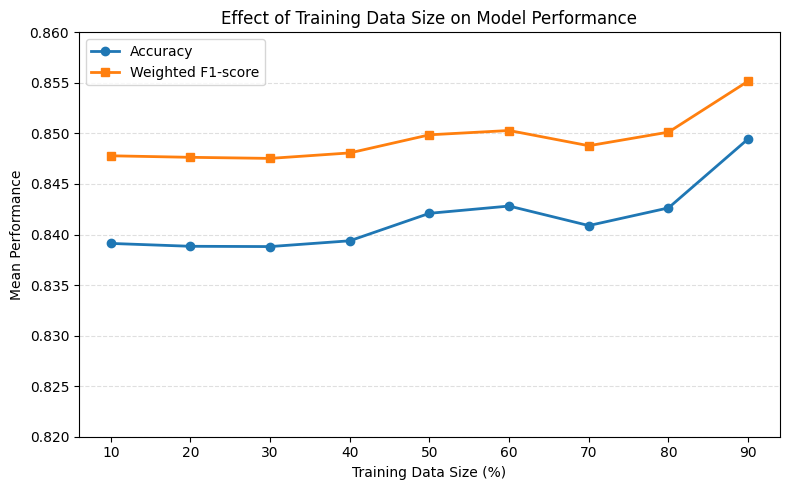

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Training Data (%)"],
    results_df["Average Accuracy"],
    marker="o",
    linewidth=2,
    label="Accuracy"
)

plt.plot(
    results_df["Training Data (%)"],
    results_df["Average F1 Score"],
    marker="s",
    linewidth=2,
    label="Weighted F1-score"
)

plt.xlabel("Training Data Size (%)")
plt.ylabel("Mean Performance")
plt.title("Effect of Training Data Size on Model Performance")

plt.xticks(range(10, 100, 10))
plt.ylim(0.82, 0.86, 0.05)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# Effect of Training Data Size on Naive Bayes Classification Performance
The purpose of this experiment was to investigate how the amount of training data affects the classification performance of a Gaussian Naive Bayes model. The model was evaluated using two performance metrics: accuracy and weighted F1-score.

The training data percentage was increased from 10% to 90% in increments of 10%. For each training data percentage, the dataset was randomly split into training and testing sets using stratified sampling to maintain approximately the same class distribution as the original dataset. The model was trained on the training set and evaluated on the testing set. Each experiment was repeated 10 times with different random seeds to examine the consistency of the results.

For each training data percentage, the average accuracy, standard deviation of accuracy, average weighted F1-score, and standard deviation of the weighted F1-score were calculated across the 10 trials. The mean values were used to compare overall classification performance, while the standard deviations were used to evaluate the variability of the results across trials.

The results show that increasing the training data generally improved the model's classification performance, although the improvement was not consistent at every step. When the training data increased from 10% to 40%, average accuracy remained nearly unchanged, ranging from 0.8388 to 0.8394. The average weighted F1-score also remained stable, between 0.8475 and 0.8481. This suggests that adding training data within this range had little impact on the model's overall performance.

A more noticeable improvement occurred as the training data increased from 40% to 60%. Average accuracy increased from 0.8394 to 0.8428, and the average weighted F1-score increased from 0.8481 to 0.8503. These results suggest that the model benefited from having more observations available to estimate the class distributions.

However, performance did not increase continuously. At 70% training data, average accuracy decreased to 0.8409, and the average weighted F1-score decreased to 0.8488. Both metrics increased again at 80%, and the highest average scores occurred at 90% training data, with an accuracy of 0.8495 and a weighted F1-score of 0.8552. These fluctuations may result from differences in the random training and testing splits rather than a negative effect of additional training data.

Importantly, a higher training percentage does not automatically guarantee better generalization. The purpose of training data is to help the model learn patterns that also apply to unseen observations. Test performance is therefore essential when evaluating whether the additional training data actually improves generalization. Overfitting is typically associated with training performance being substantially better than test performance, while underfitting is associated with poor performance on both training and testing data.                
                
The standard deviations also changed as the training data increased. The standard deviation of accuracy rose from 0.0042 at 10% training data to 0.0111 at 90%. Similarly, the standard deviation of the weighted F1-score increased from 0.0034 to 0.0068. This indicates that the results became more variable across trials at higher training percentages.

One possible explanation is that increasing the training percentage reduces the size of the testing set. At 90% training data, only 10% of the observations remain for testing, making the evaluation more sensitive to the particular observations selected. Consequently, the highest average scores at 90% should be interpreted with caution because they were accompanied by the largest standard deviations.

Another limitation concerns the assumptions of the Gaussian Naive Bayes model. It assumes that features are conditionally independent given the target class and that numerical features follow Gaussian distributions. However, customer characteristics in the Bank Marketing dataset may be related to one another, and not all numerical features necessarily follow Gaussian distributions. These assumptions may limit the model's ability to capture more complex relationships in the data.

Overall, increasing the training data from 10% to 90% was associated with a modest improvement in the Gaussian Naive Bayes model's test performance, with the largest average accuracy and weighted F1-score occurring at 90%. However, the nearly unchanged results at lower training percentages and the fluctuations at 70% and 80% show that the relationship was not strictly linear.


In conclusion, using more training data generally benefited the model in this experiment, but the highest average scores did not necessarily represent the most stable estimates of performance. Further evaluation using repeated stratified cross-validation or a separate, fixed test set would help determine whether the observed improvements generalize to unseen data. The results suggest that additional training data can help the model learn more representative patterns, but the size and composition of the testing set also affect the measured performance.